# Análise Exploratória de Dados — Valorant universitário

Adaptação do notebook de aula *Análise Exploratória de Dados* (Francisco Aparecido Rodrigues, ICMC-USP) para os dados do hackathon: 336 partidas de Valorant de campeonatos universitários (Rush Series Esquenta, Esquenta 2, Inclusivo e Univavá), já tratadas em `valorant-data-preparation.ipynb`.

<hr>

Seguimos os mesmos passos da aula, agora respondendo a perguntas reais sobre o jogo:

1. construir visualizações para variáveis numéricas (desempenho dos jogadores) e categóricas (agentes, mapas, funções);
2. interpretar histogramas, gráficos de barras, boxplots, violin plots e scatterplots;
3. calcular e interpretar medidas de posição (média, mediana, moda, quantis);
4. calcular e interpretar medidas de dispersão (variância, desvio-padrão, amplitude, IQR);
5. usar `describe()` para resumir os dados;
6. calcular e interpretar correlações de Pearson e Spearman;
7. entender por que gráficos são indispensáveis.

Ao final (seção 10), usamos essas ferramentas para analisar o **contexto competitivo**: o que decide rounds e partidas nesses campeonatos.

## 0. Preparação do ambiente

Importamos as bibliotecas e lemos as bases tratadas em `processed/`. Se elas não existirem, execute antes o notebook de preparação.

In [1]:
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import iqr, pearsonr, spearmanr

from valorant_data import aplicar_estilo, CORES, CORES_FUNCAO, ORDEM_FUNCAO

CMAP_SEQ, CMAP_DIV = aplicar_estilo()
np.random.seed(42)

pasta = Path("processed")
if not (pasta / "jogadores.csv").exists():
    raise FileNotFoundError("Execute antes o notebook valorant-data-preparation.ipynb para gerar processed/.")

data = pd.read_csv(pasta / "jogadores.csv", parse_dates=["data"])
rounds = pd.read_csv(pasta / "rounds.csv")
economia = pd.read_csv(pasta / "economia.csv")
abates = pd.read_csv(pasta / "abates.csv")

print("Jogadores x partida:", data.shape)
print("Rounds:", rounds.shape, "| Economia:", economia.shape, "| Abates:", abates.shape)
print("Partidas:", data["match_id"].nunique(), "| Jogadores:", data["puuid"].nunique(), "| Times:", data["time"].nunique())
data.head()

Jogadores x partida: (3360, 48)
Rounds: (6618, 31) | Economia: (66164, 12) | Abates: (46753, 14)
Partidas: 336 | Jogadores: 411 | Times: 68


,torneio,fase,codigo,data,match_id,mapa,versao_jogo,duracao_min,n_rounds,puuid,...,kast_pct,hs_pct,fk_round,fd_round,kpr,dpr,apr,casts_round,loadout_medio,kd_positivo
0,Rush Series Esquenta,Rush Series Esquenta,002,2026-06-06,917660a3-a85f-43c7-9fbc-c914333f642f,Ascent,release-12.10-shipping-18-4791598,37.408767,19,zsFjemN8H55MSgjZOazuxeGCfaIw6E53yC41xbIHYBpu1n...,...,68.421053,25.531915,0.368421,0.052632,0.894737,0.736842,0.315789,2.368421,4115.789474,1
1,Rush Series Esquenta,Rush Series Esquenta,002,2026-06-06,917660a3-a85f-43c7-9fbc-c914333f642f,Ascent,release-12.10-shipping-18-4791598,37.408767,19,wnvACS4SPr5Ssx3wSUtAxQ9AuWq0K7phbSkUeoYHec-pe3...,...,84.210526,34.210526,0.052632,0.000000,0.631579,0.578947,0.263158,3.105263,3318.421053,1
2,Rush Series Esquenta,Rush Series Esquenta,002,2026-06-06,917660a3-a85f-43c7-9fbc-c914333f642f,Ascent,release-12.10-shipping-18-4791598,37.408767,19,5yHUmPsPE3ZFnQjntJb5Q2-HihykkR9rfh2i-QCC1uYMuz...,...,57.894737,34.210526,0.052632,0.052632,0.736842,0.789474,0.263158,2.315789,3510.526316,0
3,Rush Series Esquenta,Rush Series Esquenta,002,2026-06-06,917660a3-a85f-43c7-9fbc-c914333f642f,Ascent,release-12.10-shipping-18-4791598,37.408767,19,dhZG1J2Fpx_6Q-4RAKkaJUk_KKT0yPiZsZvVXzmfPxZBoX...,...,89.473684,13.953488,0.052632,0.052632,0.631579,0.473684,0.578947,3.210526,3842.105263,1
4,Rush Series Esquenta,Rush Series Esquenta,002,2026-06-06,917660a3-a85f-43c7-9fbc-c914333f642f,Ascent,release-12.10-shipping-18-4791598,37.408767,19,f8hEkQ9pP_KxFUebzJa_Z4o18k0SKRQu7Embzd91LoCU4V...,...,78.947368,46.428571,0.105263,0.052632,0.842105,0.578947,0.315789,3.789474,3223.684211,1


Glossário das principais métricas (todas por partida):

| métrica | significado |
|---|---|
| `acs` | Average Combat Score — pontuação de combate média por round |
| `adr` | dano médio causado a inimigos por round |
| `kd` | kills / deaths |
| `kast_pct` | % de rounds em que o jogador teve kill, assist, sobreviveu ou teve a morte trocada |
| `hs_pct` | % de acertos na cabeça |
| `fk_round` / `fd_round` | first kills / first deaths por round (quem abre o round) |
| `casts_round` | habilidades usadas por round |

## 1. Visualização de dados

### 1.1 Histograma de frequências

Quantos abates um jogador faz em uma partida?

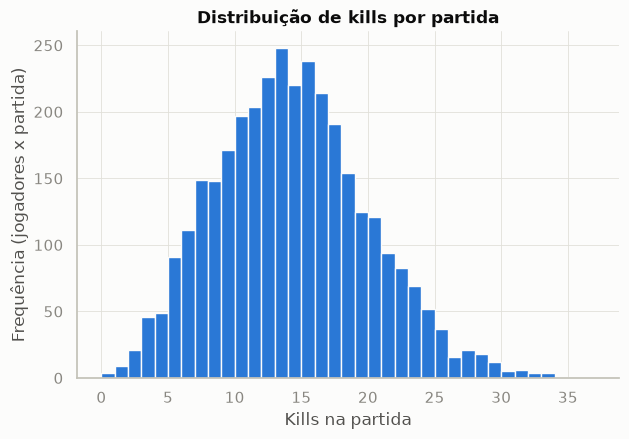

In [2]:
x = data["kills"]

plt.figure(figsize=(7, 4.5))
plt.hist(x, bins=range(0, int(x.max()) + 2), color=CORES[0])
plt.xlabel("Kills na partida")
plt.ylabel("Frequência (jogadores x partida)")
plt.title("Distribuição de kills por partida")
plt.show()

A distribuição é unimodal, concentrada entre 10 e 18 kills, com cauda à direita: poucas atuações passam de 30 kills (geralmente em partidas com prorrogação, que têm mais rounds).

### 1.2 Histograma normalizado

Com `density=True` a área total é 1 e o eixo vertical vira **densidade**. Isso permite comparar grupos de tamanhos diferentes — por exemplo, jogadores de times vencedores e perdedores.

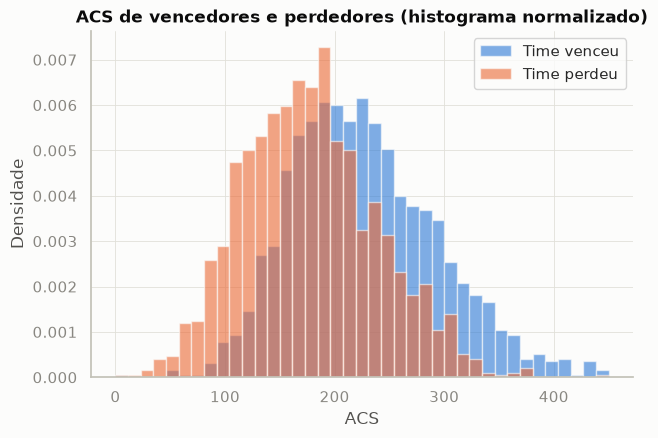

In [3]:
plt.figure(figsize=(7, 4.5))
bins = np.linspace(0, 450, 40)
plt.hist(data.loc[data["venceu"], "acs"], bins=bins, density=True, alpha=0.6, color=CORES[0], label="Time venceu")
plt.hist(data.loc[~data["venceu"], "acs"], bins=bins, density=True, alpha=0.6, color=CORES[1], label="Time perdeu")
plt.xlabel("ACS")
plt.ylabel("Densidade")
plt.title("ACS de vencedores e perdedores (histograma normalizado)")
plt.legend()
plt.show()

As duas distribuições se sobrepõem bastante, mas a dos vencedores está deslocada para a direita (≈ 50 pontos de ACS a mais em média). Um jogador com ACS alto pode perder, e um com ACS baixo pode vencer: Valorant é um jogo de equipe.

### 1.3 Gráfico de barras para variáveis categóricas

Quais agentes são mais escolhidos? Cada barra é colorida pela função do agente.

 agente      funcao  picks
   Omen Controlador    588
   Sova   Iniciador    391
Phoenix    Duelista    389
   Jett    Duelista    329
   Neon    Duelista    211
   Fade   Iniciador    202
 Cypher   Sentinela    188
   Raze    Duelista    173
Chamber   Sentinela    154
   Vyse   Sentinela    140


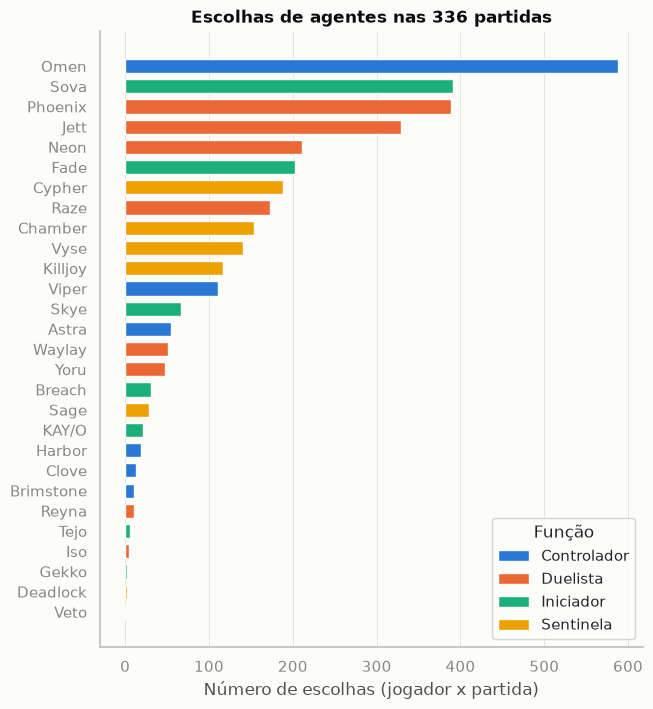

In [4]:
picks = data.groupby(["agente", "funcao"]).size().reset_index(name="picks").sort_values("picks")
print(picks.sort_values("picks", ascending=False).head(10).to_string(index=False))

plt.figure(figsize=(7, 8))
plt.barh(picks["agente"], picks["picks"], color=picks["funcao"].map(CORES_FUNCAO), height=0.7)
for funcao, cor in CORES_FUNCAO.items():
    plt.bar(0, 0, color=cor, label=funcao)
plt.xlabel("Número de escolhas (jogador x partida)")
plt.title("Escolhas de agentes nas 336 partidas")
plt.legend(title="Função", loc="lower right")
plt.grid(axis="y", visible=False)
plt.show()

O **Omen** é de longe o agente mais escolhido: está em 588 das 672 composições de time (87,5%). Em seguida vêm Sova, Phoenix e Jett. Na outra ponta, Veto, Deadlock, Gekko e Iso aparecem no máximo 4 vezes cada.

### 1.4 Gráfico de setores

O gráfico de setores mostra a proporção de cada categoria. Com apenas quatro funções ele é legível, mas diferenças pequenas (Iniciador × Sentinela) são difíceis de comparar a olho — por isso anotamos os percentuais.

funcao
Controlador     796
Duelista       1214
Iniciador       720
Sentinela       630
Name: count, dtype: int64


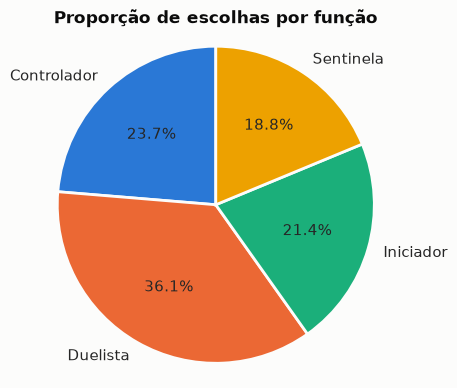

In [5]:
frequencias = data["funcao"].value_counts().reindex(ORDEM_FUNCAO)
print(frequencias)

plt.figure(figsize=(4.5, 4.5))
plt.pie(frequencias.values, labels=frequencias.index, autopct="%1.1f%%", startangle=90,
        colors=[CORES_FUNCAO[f] for f in frequencias.index], wedgeprops={"linewidth": 2, "edgecolor": "#fcfcfb"})
plt.title("Proporção de escolhas por função")
plt.axis("equal")
plt.show()

Os duelistas são 36% das escolhas: em média, quase 2 duelistas por time (1,8). A composição típica fica em torno de 2 duelistas, 1 controlador e algo próximo de 1 iniciador e 1 sentinela.

### 1.5 Scatterplot

Relação entre o dano causado por round (ADR) e o ACS.

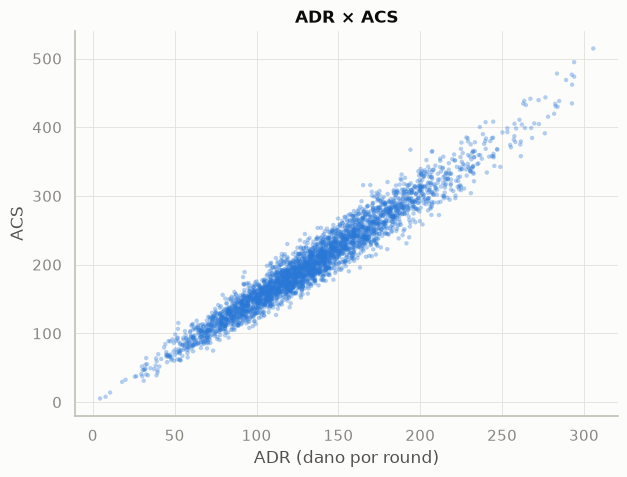

In [6]:
plt.figure(figsize=(7, 5))
plt.scatter(data["adr"], data["acs"], s=10, alpha=0.35, color=CORES[0], edgecolor="none")
plt.xlabel("ADR (dano por round)")
plt.ylabel("ACS")
plt.title("ADR × ACS")
plt.show()

Uma relação linear quase perfeita: o ACS é calculado principalmente a partir do dano. A dispersão vertical vem dos bônus por abates e multi-kills.

### 1.6 Mapa de calor

Um mapa de calor da **taxa de escolha** (% das escolhas em cada mapa) de cada agente revela o *meta* por mapa. Mantemos apenas mapas com pelo menos 10 partidas.

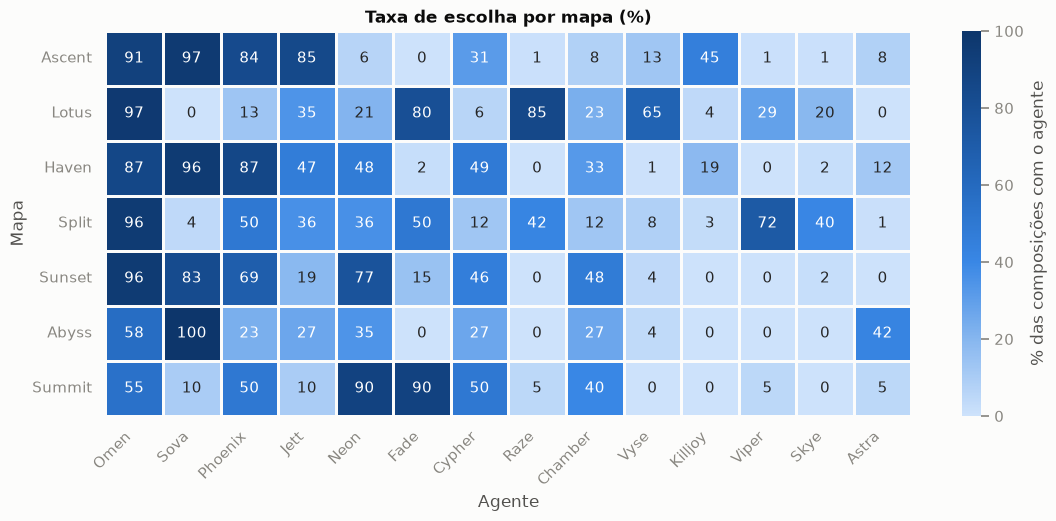

In [7]:
partidas_mapa = data.drop_duplicates("match_id")["mapa"].value_counts()
mapas = partidas_mapa[partidas_mapa >= 10].index
top_agentes = data["agente"].value_counts().head(14).index

sub = data[data["mapa"].isin(mapas)]
# % das partidas (por time) em que o agente foi escolhido naquele mapa.
pick_rate = (sub.groupby(["mapa", "agente"]).size() / (2 * sub.groupby("mapa")["match_id"].nunique()) * 100).unstack(fill_value=0)
pick_rate = pick_rate.loc[mapas, top_agentes]

plt.figure(figsize=(13, 5))
sns.heatmap(pick_rate, annot=True, fmt=".0f", cmap=CMAP_SEQ, vmin=0, vmax=100,
            cbar_kws={"label": "% das composições com o agente"}, linewidths=1, linecolor="#fcfcfb")
plt.title("Taxa de escolha por mapa (%)")
plt.xlabel("Agente")
plt.ylabel("Mapa")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.grid(False)
plt.show()

O heatmap revela escolhas específicas por mapa: o Omen está em 87–97% das composições em Ascent, Lotus, Haven, Split e Sunset, mas cai para ~55% em Abyss e Summit; o Sova é quase obrigatório em Ascent, Haven e Abyss e praticamente some em Lotus e Split; e há agentes "de mapa", como a Viper em Split (72%), a Astra em Abyss (42%), a Vyse em Lotus (65%) e o Neon em Summit (90%). Isso mostra que **o agente depende do mapa** — informação que o gráfico de barras agregado esconde.

## 2. Medidas de posição

### 2.1 Moda

A moda é o valor mais frequente e serve para variáveis categóricas e numéricas.

In [8]:
X = data["agente"].tolist()
contagem = Counter(X)
moda = contagem.most_common(1)[0]
print(f"Agente mais escolhido (moda): {moda[0]} — aparece {moda[1]} vezes")

placares = data[data["venceu"]].drop_duplicates("match_id").apply(
    lambda r: f"{int(r['rounds_ganhos_time'])}-{int(r['rounds_ganhos_adversario'])}", axis=1)
contagem_placar = Counter(placares)
print("\nPlacares mais comuns:", contagem_placar.most_common(5))

print("\nModa de kills por partida:", Counter(data["kills"]).most_common(3))

Agente mais escolhido (moda): Omen — aparece 588 vezes

Placares mais comuns: [('13-5', 44), ('13-6', 37), ('13-11', 32), ('13-8', 31), ('13-7', 30)]

Moda de kills por partida: [(13.0, 248), (15.0, 238), (12.0, 226)]


Uma distribuição pode ter **mais de uma moda** (multimodal). Por exemplo, a moda do agente escolhido dentro de cada função e, dentro de cada time, o mapa mais jogado:

In [9]:
def modas(valores):
    contagem = Counter(valores)
    maior_frequencia = max(contagem.values())
    return [valor for valor, freq in contagem.items() if freq == maior_frequencia], maior_frequencia

for funcao in ORDEM_FUNCAO:
    m, f = modas(data.loc[data["funcao"] == funcao, "agente"])
    print(f"{funcao:12s}: moda = {m} ({f} escolhas)")

times_multimodais = {}
for time, grupo in data.drop_duplicates(["match_id", "time"]).groupby("time"):
    m, f = modas(grupo["mapa"])
    if len(m) > 1 and f >= 3:
        times_multimodais[time] = (m, f)
print("\nTimes com mais de um mapa 'mais jogado' (multimodal):")
for time, (m, f) in list(times_multimodais.items())[:6]:
    print(f"  {time:25s} {m} — {f} partidas cada")

Controlador : moda = ['Omen'] (588 escolhas)
Duelista    : moda = ['Phoenix'] (389 escolhas)
Iniciador   : moda = ['Sova'] (391 escolhas)
Sentinela   : moda = ['Cypher'] (188 escolhas)

Times com mais de um mapa 'mais jogado' (multimodal):
  Azure Bears Black         ['Haven', 'Split'] — 10 partidas cada
  Green Owls Noctua         ['Haven', 'Ascent'] — 4 partidas cada
  Octacore Javascript       ['Haven', 'Lotus'] — 3 partidas cada


Também podemos visualizar a moda por meio de um gráfico de barras — aqui, os placares finais mais frequentes.

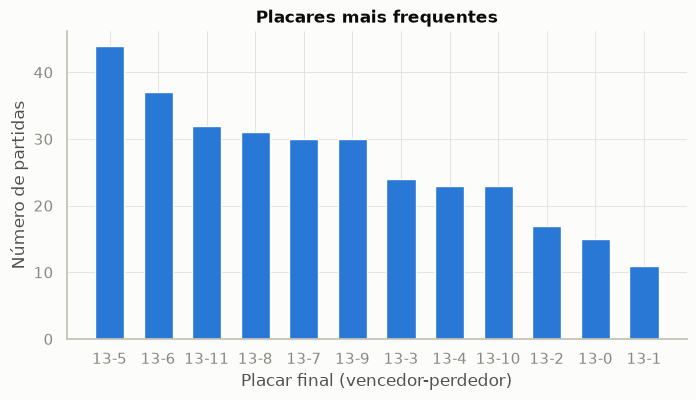

In [10]:
frequencias_placar = pd.Series(contagem_placar).sort_values(ascending=False).head(12)

plt.figure(figsize=(8, 4))
plt.bar(frequencias_placar.index, frequencias_placar.values, color=CORES[0], width=0.6)
plt.xlabel("Placar final (vencedor-perdedor)")
plt.ylabel("Número de partidas")
plt.title("Placares mais frequentes")
plt.show()

### 2.2 Média e mediana

A média é sensível a valores extremos; a mediana é robusta. O KD é um bom exemplo: um jogador que termina com 16 kills e 1 death tem KD = 16, puxando a média para cima.

In [11]:
X = data["kd"]
print("KD — média:", round(np.mean(X), 3), "| mediana:", round(np.median(X), 3))

# Agora retiramos o 1% de valores mais altos de KD.
X2 = X[X <= X.quantile(0.99)]
print("Sem o 1% maior — média:", round(np.mean(X2), 3), "| mediana:", round(np.median(X2), 3))
print("Maiores KDs:", X.sort_values(ascending=False).head(5).round(2).tolist())

KD — média: 1.157 | mediana: 1.0
Sem o 1% maior — média: 1.101 | mediana: 1.0
Maiores KDs: [16.0, 12.0, 11.0, 10.5, 10.0]


Remover apenas 34 valores (1%) reduz a média em ~0,06, enquanto a mediana não se altera. Em distribuições assimétricas, a mediana representa melhor o "jogador típico".

### 2.3 Média e mediana em distribuições diferentes

Em distribuições aproximadamente simétricas (como o ADR), média e mediana são próximas. Em distribuições assimétricas (como o KD, que é uma razão), elas se afastam.

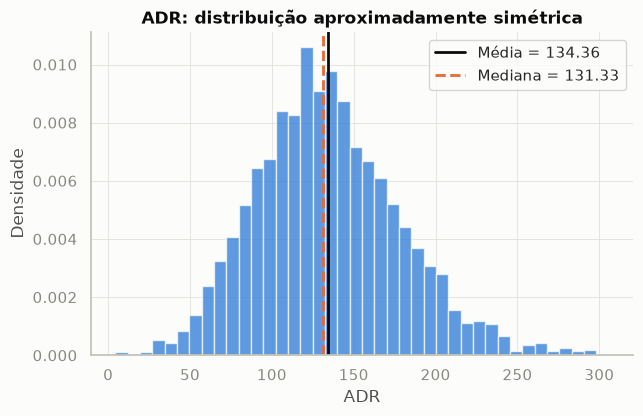

adr: assimetria (skewness) = 0.43


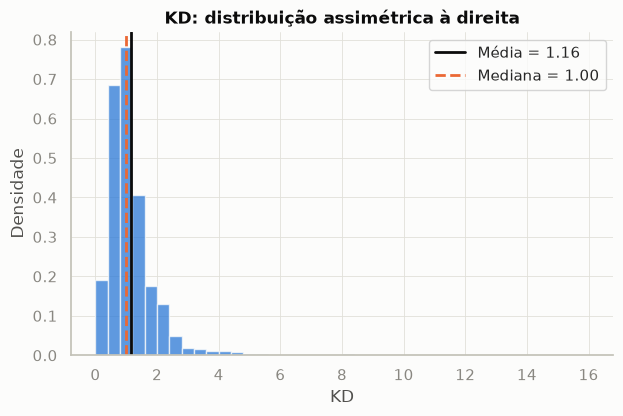

kd: assimetria (skewness) = 4.97


In [12]:
for coluna, titulo in [("adr", "ADR: distribuição aproximadamente simétrica"), ("kd", "KD: distribuição assimétrica à direita")]:
    valores = data[coluna]
    plt.figure(figsize=(7, 4.2))
    plt.hist(valores, bins=40, density=True, color=CORES[0], alpha=0.75)
    plt.axvline(valores.mean(), color="#0b0b0b", label=f"Média = {valores.mean():.2f}", linewidth=2)
    plt.axvline(valores.median(), color=CORES[1], label=f"Mediana = {valores.median():.2f}", linewidth=2, linestyle="--")
    plt.xlabel(coluna.upper())
    plt.ylabel("Densidade")
    plt.title(titulo)
    plt.legend()
    plt.show()
    print(f"{coluna}: assimetria (skewness) = {valores.skew():.2f}")

### 2.4 Quantis

Os quartis dividem os dados ordenados em quatro partes, e o intervalo interquartil é

$$
IQR = Q_3 - Q_1.
$$

Pela regra de Tukey, valores acima de $Q_3 + 1{,}5\,IQR$ são considerados *outliers* — aqui, atuações excepcionais.

In [13]:
x = data["acs"]
q1 = np.quantile(x, 0.25)
q2 = np.quantile(x, 0.50)
q3 = np.quantile(x, 0.75)

print("ACS — média:", round(np.mean(x), 1), "| mediana:", round(np.median(x), 1))
print("Primeiro quartil Q1:", round(q1, 1))
print("Segundo quartil Q2:", round(q2, 1))
print("Terceiro quartil Q3:", round(q3, 1))
print("Intervalo interquartil IQR:", round(q3 - q1, 1))

limite = q3 + 1.5 * (q3 - q1)
print(f"\nLimite superior (Q3 + 1,5·IQR): {limite:.1f}  ->  {(x > limite).sum()} atuações acima")
data.loc[x > limite, ["jogador", "time", "adversario", "agente", "mapa", "kills", "deaths", "acs", "venceu"]] \
    .sort_values("acs", ascending=False).head(10)

ACS — média: 202.7 | mediana: 195.7
Primeiro quartil Q1: 155.2
Segundo quartil Q2: 195.7
Terceiro quartil Q3: 245.1
Intervalo interquartil IQR: 90.0

Limite superior (Q3 + 1,5·IQR): 380.1  ->  44 atuações acima


,jogador,time,adversario,agente,mapa,kills,deaths,acs,venceu
593,lule#dfnt,Macklogic Rainbow,Caap Auroras,Jett,Ascent,33.0,10.0,514.611111,True
608,lule#dfnt,Macklogic Rainbow,Azure Bears White,Jett,Split,28.0,8.0,494.666667,True
370,leoZinn#LM8,Totale Umc,Inatel Gray,Neon,Haven,23.0,6.0,478.071429,True
775,andre#aaa12,Azure Bears Golden,Fei Darkowls,Phoenix,Ascent,25.0,5.0,476.461538,True
1825,TORONTO#lulu,Minerva Thunders,Maua Blue,Jett,Lotus,30.0,9.0,473.611111,True
2130,Noya#Lilos,Green Owls Jacurutu,Inatel Dois,Omen,Haven,28.0,7.0,468.750000,True
2213,CAAP protanzy42#sobru,Caap Malditos,Gambiarra Ufg,Phoenix,Ascent,31.0,11.0,462.000000,True
15,ninker#tbest,A2E Uff,Ufu Saints Auryn,Jett,Ascent,22.0,8.0,443.384615,True
1253,haku#moca,Octacore Python,Inatel Gray,Raze,Lotus,25.0,9.0,441.466667,True
1480,J3YP#END,Ceub Octopus Vulgaris,Ime Wolves Red,Jett,Haven,25.0,6.0,439.375000,True


### 2.5 Boxplot

O boxplot resume a distribuição com a mediana, o IQR (caixa) e os possíveis valores extremos (pontos).

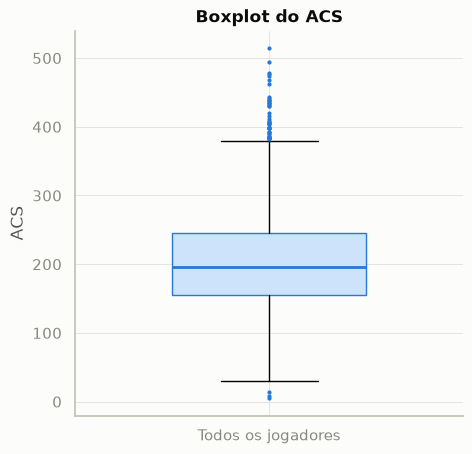

In [14]:
plt.figure(figsize=(5, 5))
plt.boxplot(data["acs"], widths=0.5, patch_artist=True,
            boxprops={"facecolor": "#cde2fb", "edgecolor": CORES[0]}, medianprops={"color": CORES[0], "linewidth": 2},
            flierprops={"markersize": 3, "markerfacecolor": CORES[0], "markeredgecolor": "none"})
plt.xticks([1], ["Todos os jogadores"])
plt.ylabel("ACS")
plt.title("Boxplot do ACS")
plt.show()

## 3. Comparando grupos: funções dos agentes

No notebook original, comparávamos as espécies da Iris. Aqui, o grupo natural é a **função** do agente: duelistas são feitos para abrir espaço e matar; controladores, iniciadores e sentinelas cumprem papéis de suporte.

### 3.1 Boxplot por função

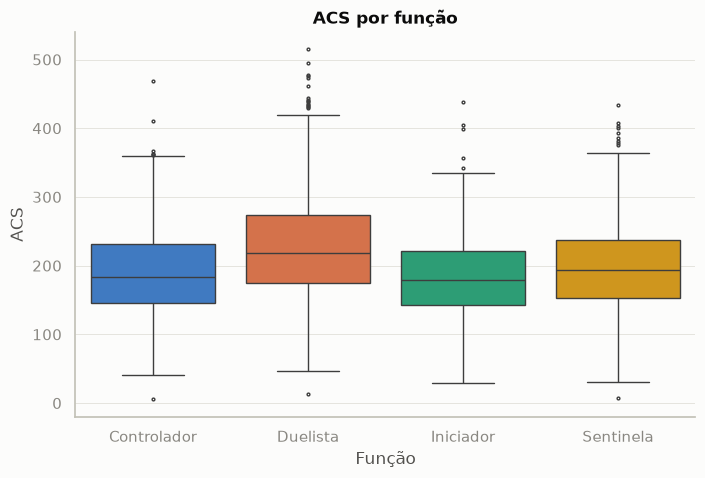

In [15]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="funcao", y="acs", hue="funcao", order=ORDEM_FUNCAO, palette=CORES_FUNCAO,
            legend=False, linewidth=1, fliersize=2)
plt.xlabel("Função")
plt.ylabel("ACS")
plt.title("ACS por função")
plt.show()

Os duelistas têm o ACS mais alto (mediana ≈ 220), como esperado pelo papel ofensivo. As sentinelas aparecem em segundo — curiosamente acima de controladores e iniciadores. O responsável é a Chamber (ACS médio 217, próximo ao dos duelistas), cujas habilidades são armas (Headhunter e Tour de Force); as demais sentinelas ficam entre 189 e 198.

### 3.2 Violin plot

O violin plot acrescenta a densidade estimada. Usamos o **first kill por round**, que mede quem "abre" o round.

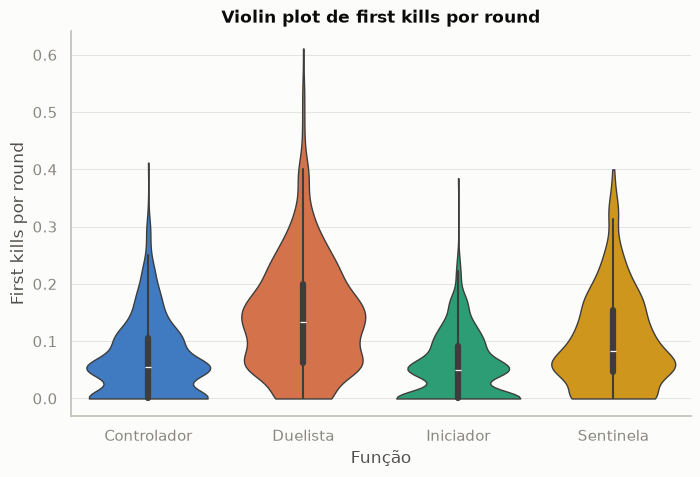

In [16]:
plt.figure(figsize=(8, 5))
sns.violinplot(data=data, x="funcao", y="fk_round", hue="funcao", order=ORDEM_FUNCAO, palette=CORES_FUNCAO,
               legend=False, cut=0, linewidth=1)
plt.xlabel("Função")
plt.ylabel("First kills por round")
plt.title("Violin plot de first kills por round")
plt.show()

Duelistas fazem o dobro de first kills que controladores e iniciadores (0,14 contra 0,06–0,07 por round). O formato dos violinos também difere: para controladores e iniciadores, a densidade se concentra perto de zero (raramente abrem o round), enquanto a dos duelistas é mais espalhada.

### 3.3 Swarm plot

O swarm plot mostra cada observação. Com 3.360 linhas ele ficaria ilegível, então usamos as **336 partidas** e olhamos a duração por mapa.

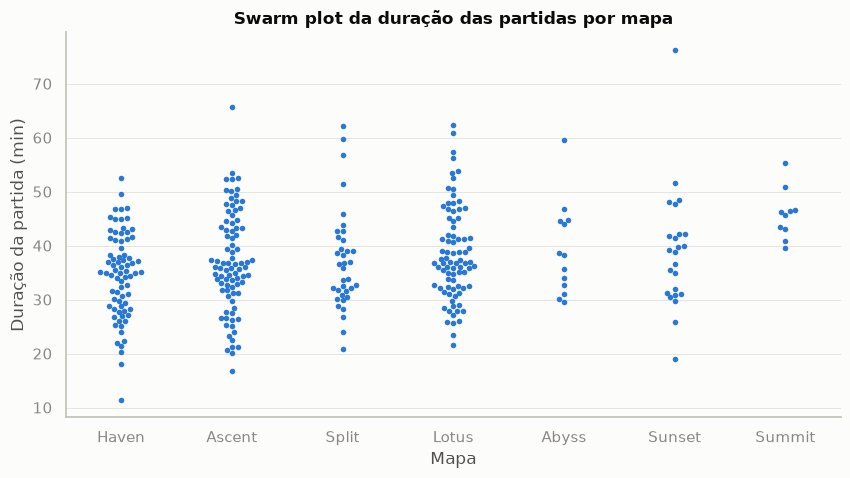

        count  mean  median
mapa                       
Haven      75  19.1    19.0
Ascent     86  19.4    19.0
Split      36  19.5    18.0
Lotus      82  20.2    20.0
Abyss      13  20.4    20.0
Sunset     24  19.9    20.0
Summit     10  22.5    22.0


In [17]:
partidas = data.drop_duplicates("match_id")
partidas = partidas[partidas["mapa"].isin(mapas)]
ordem_mapas = partidas.groupby("mapa")["duracao_min"].median().sort_values().index

plt.figure(figsize=(10, 5))
sns.swarmplot(data=partidas, x="mapa", y="duracao_min", order=ordem_mapas, size=4, color=CORES[0])
plt.xlabel("Mapa")
plt.ylabel("Duração da partida (min)")
plt.title("Swarm plot da duração das partidas por mapa")
plt.show()

print(partidas.groupby("mapa")["n_rounds"].agg(["count", "mean", "median"]).round(1).loc[ordem_mapas])

A duração típica fica entre 30 e 45 minutos em todos os mapas; os pontos isolados no topo são partidas com prorrogação. Summit tem as partidas mais longas (22,5 rounds em média), mas com apenas 10 partidas.

## 4. Medidas de dispersão

Duas amostras podem ter a mesma média e dispersões muito diferentes. Em Valorant isso é a diferença entre um jogador **consistente** e um **instável**. Procuramos dois jogadores (com pelo menos 10 partidas) com ACS médio quase igual e desvios-padrão muito diferentes.

In [18]:
def variancia_amostral(valores):
    # Calcula a variância amostral usando denominador n - 1.
    valores = np.asarray(valores)
    media = np.mean(valores)
    return np.sum((valores - media) ** 2) / (len(valores) - 1)

resumo = data.groupby("puuid").agg(jogador=("jogador", "first"), partidas=("match_id", "size"),
                                   media=("acs", "mean"), dp=("acs", "std")).query("partidas >= 10")

# Para cada par de jogadores com médias a menos de 3 pontos, escolhemos o de maior razão entre desvios.
melhor = None
for i, a in resumo.iterrows():
    proximos = resumo[(resumo["media"] - a["media"]).abs() < 3]
    for j, b in proximos.iterrows():
        razao = a["dp"] / b["dp"]
        if melhor is None or razao > melhor[0]:
            melhor = (razao, i, j)
_, id_x, id_y = melhor

for puuid in [id_x, id_y]:
    valores = data.loc[data["puuid"] == puuid, "acs"]
    print(f"Jogador {resumo.loc[puuid, 'jogador']} ({len(valores)} partidas)")
    print("  Média:", round(np.mean(valores), 1))
    print("  Variância amostral:", round(variancia_amostral(valores), 1))
    print("  Desvio-padrão amostral:", round(np.std(valores, ddof=1), 1))
    print("  IQR:", round(iqr(valores), 1))
    print("  Amplitude:", round(np.max(valores) - np.min(valores), 1))
    print()

Jogador floquinho67#9 10 (12 partidas)
  Média: 161.0
  Variância amostral: 5481.3
  Desvio-padrão amostral: 74.0
  IQR: 77.0
  Amplitude: 251.7

Jogador Doragon#Ana (11 partidas)
  Média: 158.8
  Variância amostral: 743.1
  Desvio-padrão amostral: 27.3
  IQR: 29.5
  Amplitude: 84.9



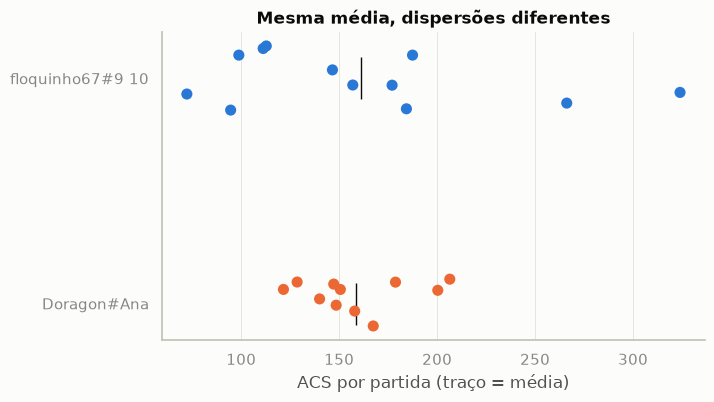

In [19]:
dois = data[data["puuid"].isin([id_x, id_y])]
plt.figure(figsize=(7, 4))
sns.stripplot(data=dois, x="acs", y="jogador", hue="jogador", palette=CORES[:2], size=8, jitter=0.15, legend=False)
for k, puuid in enumerate([id_x, id_y]):
    plt.plot(dois.loc[dois["puuid"] == puuid, "acs"].mean(), k, marker="|", markersize=30, color="#0b0b0b")
plt.xlabel("ACS por partida (traço = média)")
plt.ylabel("")
plt.title("Mesma média, dispersões diferentes")
plt.show()

Os dois jogadores entregam, em média, o mesmo ACS, mas um deles oscila muito mais entre partidas. Só a média não distinguiria os dois perfis — as medidas de dispersão (e o gráfico) sim.

## 5. Resumo descritivo com Pandas

O método `describe()` fornece contagem, média, desvio-padrão, mínimo, quartis e máximo.

In [20]:
metricas = ["acs", "adr", "kd", "kast_pct", "hs_pct", "fk_round", "fd_round", "apr", "casts_round"]
data[metricas].describe().round(2)

,acs,adr,kd,kast_pct,hs_pct,fk_round,fd_round,apr,casts_round
count,3360.00,3360.00,3360.00,3360.00,3360.00,3360.00,3360.00,3360.00,3360.00
mean,202.73,134.36,1.16,70.97,26.63,0.10,0.10,0.27,2.54
std,69.72,44.28,0.89,14.56,10.43,0.09,0.08,0.17,0.73
min,5.27,4.43,0.00,14.29,0.00,0.00,0.00,0.00,0.37
25%,155.16,104.38,0.67,61.90,19.14,0.04,0.05,0.15,2.04
50%,195.73,131.33,1.00,72.73,25.64,0.08,0.09,0.25,2.46
75%,245.13,162.00,1.38,81.25,33.33,0.15,0.15,0.35,3.00
max,514.61,305.67,16.00,100.00,90.00,0.61,0.47,1.29,5.08


Também podemos obter o resumo por grupos — aqui, por função.

In [21]:
data.groupby("funcao")[["acs", "kd", "kast_pct", "fk_round", "apr", "casts_round"]].describe().T.round(2)

funcao             Controlador  Duelista  Iniciador  Sentinela
acs         count       796.00   1214.00     720.00     630.00
            mean        189.41    225.64     182.20     198.88
            std          63.75     74.47      59.56      65.88
            min           5.27     13.90      29.43       7.77
            25%         146.16    174.19     142.48     153.35
            50%         183.39    219.12     178.56     194.40
            75%         232.11    273.28     221.54     237.94
            max         468.75    514.61     438.47     434.06
kd          count       796.00   1214.00     720.00     630.00
            mean          1.11      1.19       1.11       1.20
            std           0.83      0.75       0.93       1.13
            min           0.00      0.08       0.00       0.00
            25%           0.64      0.71       0.61       0.69
            50%           0.95      1.00       0.93       1.00
            75%           1.37      1.44       1.29       1.40
            max           8.00      5.67      10.50      16.00
kast_pct    count       796.00   1214.00     720.00     630.00
            mean         71.97     70.97      71.83      68.72
            std          14.60     14.07      15.43      14.21
            min          15.38     15.38      14.29      15.38
            25%          63.16     61.54      62.50      60.00
            50%          73.68     72.47      73.68      70.00
            75%          82.35     80.95      83.33      78.95
            max         100.00    100.00     100.00     100.00
fk_round    count       796.00   1214.00     720.00     630.00
            mean          0.07      0.14       0.06       0.10
            std           0.07      0.10       0.06       0.08
            min           0.00      0.00       0.00       0.00
            25%           0.00      0.06       0.00       0.05
            50%           0.06      0.13       0.05       0.08
            75%           0.11      0.20       0.09       0.15
            max           0.41      0.61       0.38       0.40
apr         count       796.00   1214.00     720.00     630.00
            mean          0.35      0.23       0.31       0.19
            std           0.18      0.14       0.17       0.12
            min           0.00      0.00       0.00       0.00
            25%           0.22      0.13       0.19       0.11
            50%           0.33      0.21       0.29       0.17
            75%           0.46      0.31       0.41       0.27
            max           1.29      0.92       1.13       0.75
casts_round count       796.00   1214.00     720.00     630.00
            mean          2.92      2.08       2.70       2.76
            std           0.67      0.48       0.61       0.87
            min           0.53      0.37       0.67       0.37
            25%           2.44      1.80       2.32       2.09
            50%           2.95      2.09       2.71       2.61
            75%           3.43      2.41       3.10       3.40
            max           4.60      3.77       4.30       5.08

O resumo por grupos confirma os papéis: duelistas lideram em ACS e first kills e usam menos habilidades (2,1 por round); controladores e iniciadores lideram em assistências (0,35 e 0,31 por round); sentinelas têm a menor taxa de assistências, coerente com o papel de segurar um lado do mapa sozinhas. O KAST é parecido entre as funções (≈ 69–72%): todos contribuem para o round de alguma forma.

## 6. Correlação

- **Pearson**: associação linear;
- **Spearman**: associação monotônica, baseada nos postos.

Importante: correlação não implica causalidade.

### 6.1 Correlação de Pearson

No notebook original, a correlação diminuía com o aumento do ruído artificial. Aqui vemos pares reais de métricas com correlações cada vez menores.

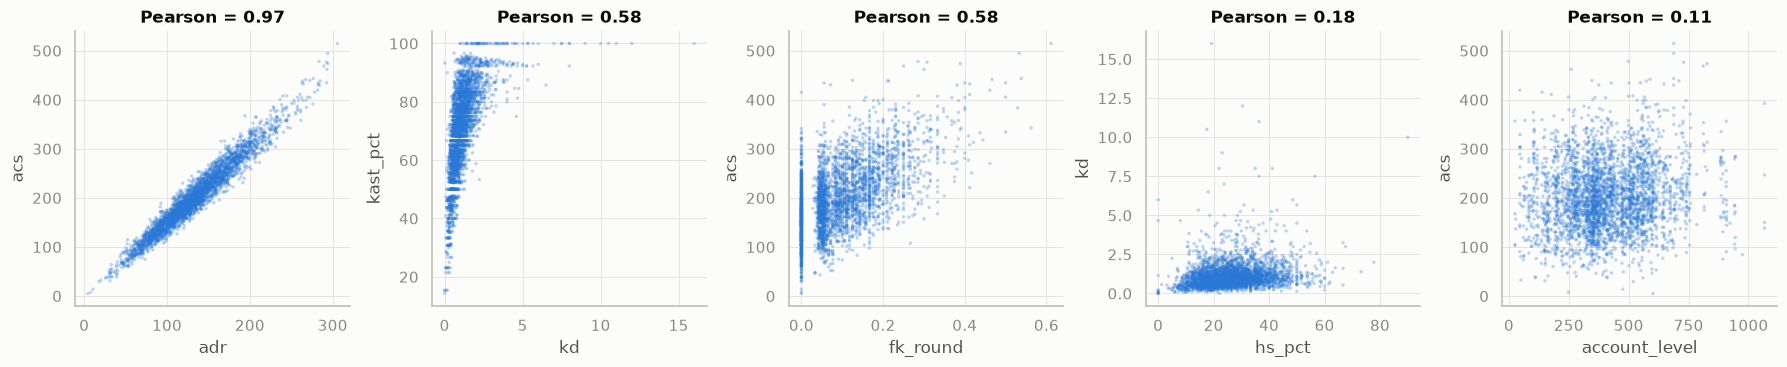

In [22]:
pares = [("adr", "acs"), ("kd", "kast_pct"), ("fk_round", "acs"), ("hs_pct", "kd"), ("account_level", "acs")]

fig, axs = plt.subplots(1, len(pares), figsize=(18, 3.8))
for ax, (a, b) in zip(axs, pares):
    corr, p_value = pearsonr(data[a], data[b])
    ax.scatter(data[a], data[b], s=6, alpha=0.3, color=CORES[0], edgecolor="none")
    ax.set_title(f"Pearson = {corr:.2f}")
    ax.set_xlabel(a)
    ax.set_ylabel(b)
plt.tight_layout()
plt.show()

À medida que a relação linear fica menos evidente, a correlação se aproxima de zero. O nível da conta (`account_level`, ligado ao tempo de jogo) quase não tem relação com o desempenho (r ≈ 0,11): **jogar há mais tempo não garante ACS mais alto**.

### 6.2 Matriz de correlação

Com várias variáveis, calculamos a matriz de correlação. Exemplo no nível de **time por partida**: rounds ganhos versus o ADR, o KAST e os first kills médios do time.

               rounds_ganhos    adr   kast  first_kills
rounds_ganhos          1.000  0.781  0.824        0.724
adr                    0.781  1.000  0.852        0.593
kast                   0.824  0.852  1.000        0.586
first_kills            0.724  0.593  0.586        1.000


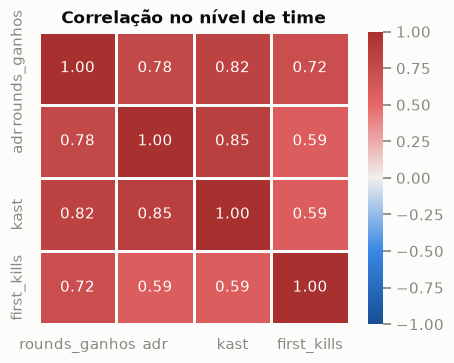

In [23]:
time_partida = data.groupby(["match_id", "time"]).agg(
    rounds_ganhos=("rounds_ganhos_time", "first"),
    adr=("adr", "mean"), kast=("kast_pct", "mean"), first_kills=("first_kills", "sum"))

corr = time_partida.corr()
print(corr.round(3))

plt.figure(figsize=(5, 3.8))
sns.heatmap(corr, annot=True, cmap=CMAP_DIV, vmin=-1, vmax=1, fmt=".2f", linewidths=1, linecolor="#fcfcfb")
plt.title("Correlação no nível de time")
plt.grid(False)
plt.show()

### 6.3 Correlação entre as métricas dos jogadores

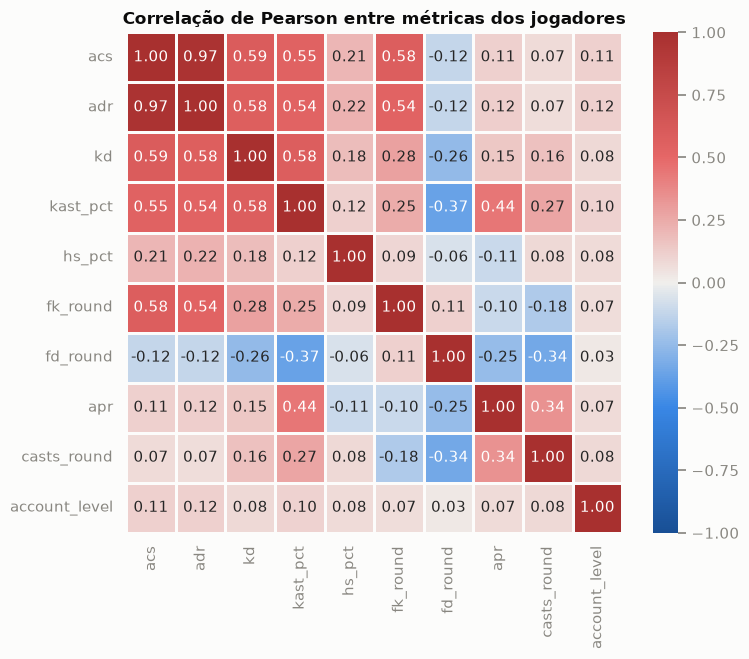

In [24]:
variaveis_numericas = ["acs", "adr", "kd", "kast_pct", "hs_pct", "fk_round", "fd_round", "apr", "casts_round", "account_level"]
corr_jog = data[variaveis_numericas].corr()

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr_jog, annot=True, fmt=".2f", cmap=CMAP_DIV, vmin=-1, vmax=1, linewidths=1, linecolor="#fcfcfb")
plt.title("Correlação de Pearson entre métricas dos jogadores")
plt.grid(False)
plt.show()

Destaques: ACS e ADR (0,97) são quase redundantes; o KAST está ligado ao KD (0,58) e às assistências; first deaths correlaciona negativamente com KAST (quem morre primeiro raramente é trocado e não sobrevive). O HS% é quase independente de tudo — mirar na cabeça é uma habilidade distinta de "estar no lugar certo".

### 6.4 Pair plot

O pair plot mostra as relações entre todos os pares. Usamos uma amostra de 800 linhas para manter o gráfico legível; as funções têm cor **e** marcador diferentes.

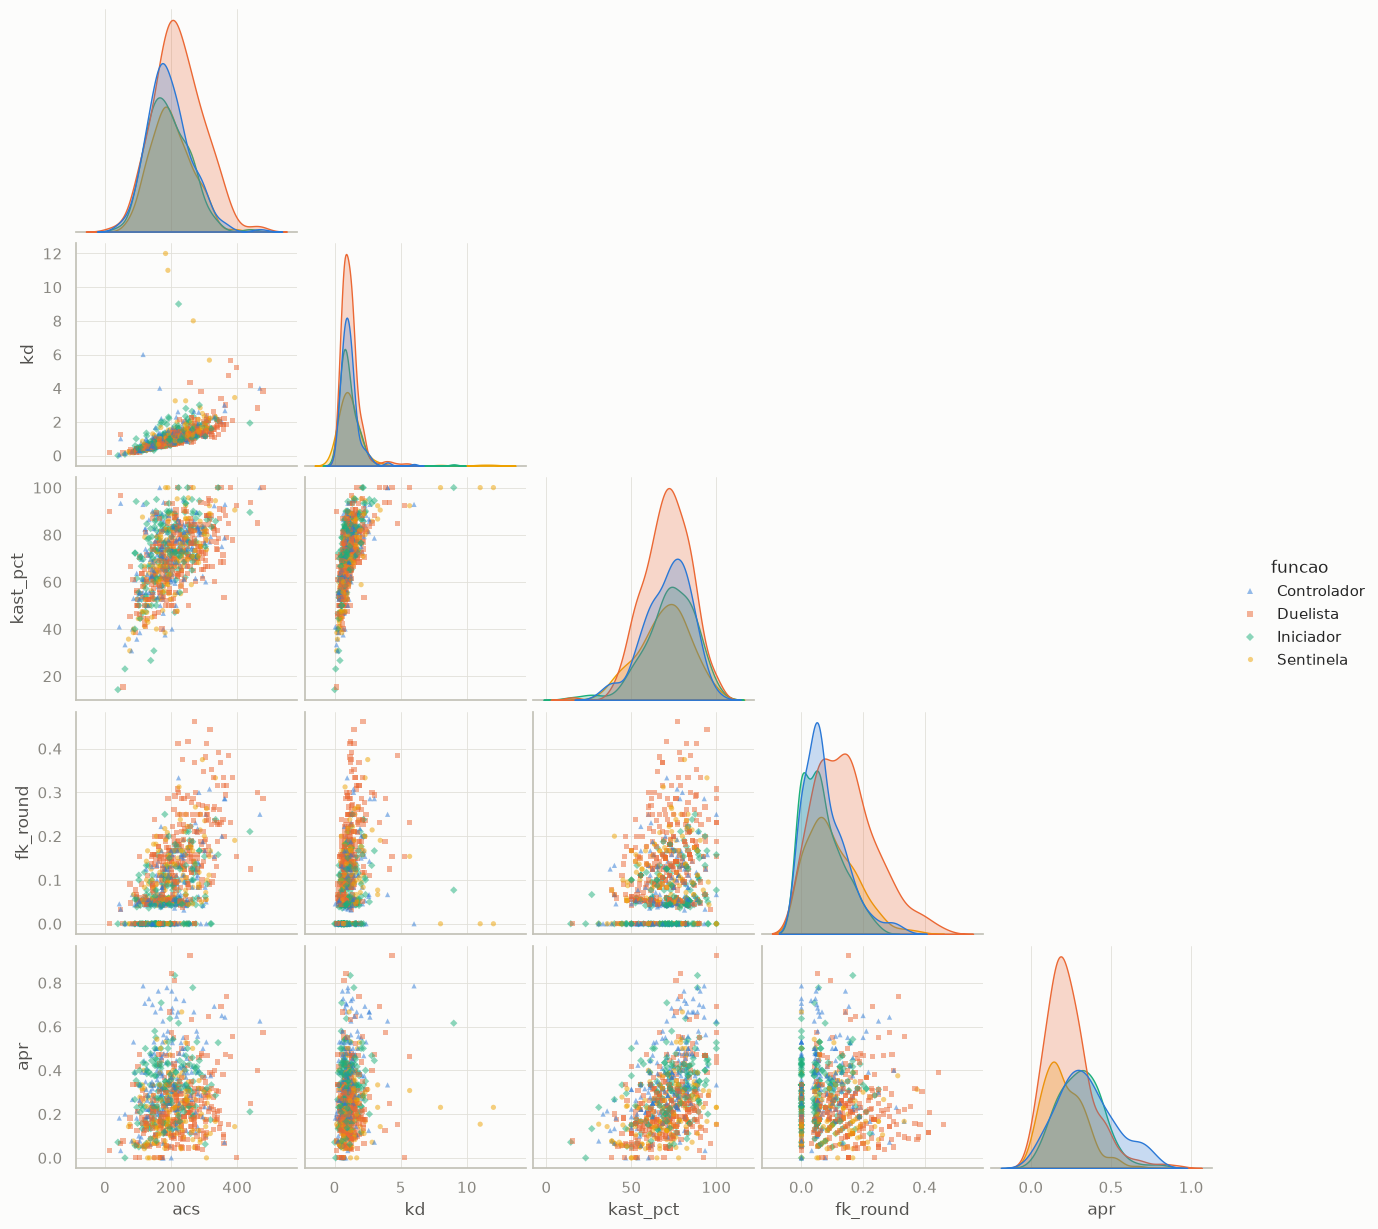

In [25]:
import warnings
warnings.filterwarnings("ignore")

amostra = data.sample(800, random_state=42)
sns.pairplot(
    amostra,
    vars=["acs", "kd", "kast_pct", "fk_round", "apr"],
    hue="funcao",
    hue_order=ORDEM_FUNCAO,
    palette=CORES_FUNCAO,
    markers=["o", "s", "D", "^"],
    diag_kind="kde",
    corner=True,
    plot_kws={"s": 14, "alpha": 0.5, "edgecolor": "none"},
)
plt.show()

Diferente da Iris, as funções **não formam grupos separados**: há grande sobreposição. Apenas `fk_round` (duelistas mais à direita) e `apr` (duelistas mais abaixo) sugerem diferenças. Isso indica que prever a função de um jogador só pelas estatísticas seria difícil.

### 6.5 Correlação de Spearman

O KD é uma **razão** (kills / deaths): cresce de forma muito acelerada quando as mortes são poucas e tem cauda longa (KD de até 16). A relação entre ACS e KD é monotônica — quem tem mais ACS tende a ter mais KD — mas curva e com *outliers*. É exatamente o caso em que Spearman e Pearson divergem.

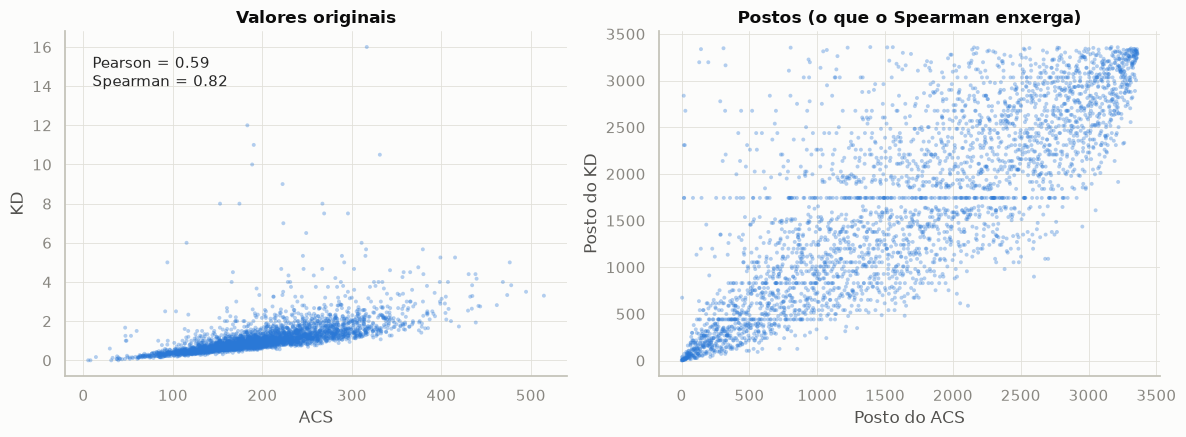

Correlação de Pearson: 0.594
Correlação de Spearman: 0.817


In [26]:
x = data["acs"]
z = data["kd"]
corr_pearson, _ = pearsonr(x, z)
corr_spearman, _ = spearmanr(x, z)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
axs[0].scatter(x, z, s=8, alpha=0.35, color=CORES[0], edgecolor="none")
axs[0].set_xlabel("ACS")
axs[0].set_ylabel("KD")
axs[0].set_title("Valores originais")
axs[0].text(10, 14, f"Pearson = {corr_pearson:.2f}\nSpearman = {corr_spearman:.2f}", fontsize=11)

axs[1].scatter(x.rank(), z.rank(), s=8, alpha=0.35, color=CORES[0], edgecolor="none")
axs[1].set_xlabel("Posto do ACS")
axs[1].set_ylabel("Posto do KD")
axs[1].set_title("Postos (o que o Spearman enxerga)")
plt.tight_layout()
plt.show()

print("Correlação de Pearson:", round(corr_pearson, 3))
print("Correlação de Spearman:", round(corr_spearman, 3))

Nos valores originais, os poucos KDs muito altos e a curvatura "achatam" o Pearson (0,59). Nos postos, a nuvem é bem mais alinhada e o Spearman chega a 0,82. Comparando as duas correlações para todas as métricas, os pares com maior diferença envolvem justamente o KD:

In [27]:
pearson_m = data[variaveis_numericas].corr(method="pearson")
spearman_m = data[variaveis_numericas].corr(method="spearman")
diferenca = (spearman_m - pearson_m).where(np.triu(np.ones(pearson_m.shape, dtype=bool), k=1)).stack().dropna()
print("Pares com maior diferença Spearman − Pearson:")
print(diferenca.reindex(diferenca.abs().sort_values(ascending=False).index).head(6).round(3))

Pares com maior diferença Spearman − Pearson:
acs  kd             0.222
adr  kd             0.211
kd   kast_pct       0.144
     fk_round       0.095
     hs_pct         0.056
     casts_round    0.048
dtype: float64


## 7. Implementação manual das correlações

Implementamos o desvio-padrão e as correlações manualmente e comparamos com o `scipy`, usando ADR e ACS.

In [28]:
x = data["adr"].to_numpy()
y = data["acs"].to_numpy()

def desvio_padrao_populacional(vetor):
    # Calcula o desvio-padrão populacional.
    vetor = np.asarray(vetor)
    media = np.mean(vetor)
    return np.sqrt(np.mean((vetor - media) ** 2))

print("Desvio-padrão — função implementada:", desvio_padrao_populacional(x))
print("Desvio-padrão — NumPy:              ", np.std(x))

Desvio-padrão — função implementada: 44.27776850223286
Desvio-padrão — NumPy:               44.27776850223286


In [29]:
def pearson_manual(x, y):
    # Calcula a correlação de Pearson manualmente.
    x = np.asarray(x)
    y = np.asarray(y)
    covariancia = np.mean((x - np.mean(x)) * (y - np.mean(y)))
    return covariancia / (np.std(x) * np.std(y))

print("Pearson manual:      ", pearson_manual(x, y))
print("Pearson usando scipy:", pearsonr(x, y)[0])

Pearson manual:       0.9732765853401271
Pearson usando scipy: 0.9732765853401271


Para Spearman, basta transformar os valores em postos e aplicar Pearson aos postos.

In [30]:
x_rank = pd.Series(x).rank().to_numpy()
y_rank = pd.Series(y).rank().to_numpy()

print("Spearman manual:      ", pearson_manual(x_rank, y_rank))
print("Spearman usando scipy:", spearmanr(x, y)[0])

Spearman manual:       0.9697666319200888
Spearman usando scipy: 0.9697666319200889


## 8. Por que gráficos são indispensáveis?

O **quarteto de Anscombe** mostra quatro conjuntos com médias, variâncias e correlações iguais, mas padrões completamente diferentes.

In [31]:
x1 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y1 = [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]
y2 = [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]
y3 = [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]
x4 = [8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8]
y4 = [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]

anscombe = {"I": (x1, y1), "II": (x1, y2), "III": (x1, y3), "IV": (x4, y4)}

resumo = []
for nome, (xx, yy) in anscombe.items():
    resumo.append({"conjunto": nome, "media_x": np.mean(xx), "media_y": np.mean(yy),
                   "var_x": np.var(xx, ddof=1), "var_y": np.var(yy, ddof=1), "correlacao": pearsonr(xx, yy)[0]})
pd.DataFrame(resumo).round(2)

,conjunto,media_x,media_y,var_x,var_y,correlacao
0,I,9.0,7.5,11.0,4.13,0.82
1,II,9.0,7.5,11.0,4.13,0.82
2,III,9.0,7.5,11.0,4.12,0.82
3,IV,9.0,7.5,11.0,4.12,0.82


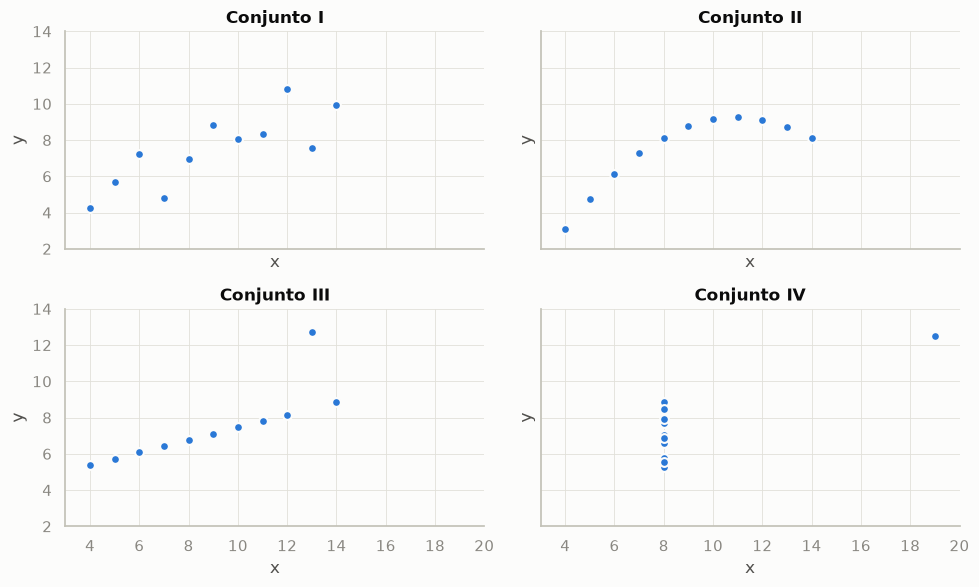

In [32]:
fig, axs = plt.subplots(2, 2, sharex=True, sharey=True, figsize=(10, 6))
for ax, (nome, (xx, yy)) in zip(axs.flat, anscombe.items()):
    ax.scatter(xx, yy, s=40, color=CORES[0], edgecolor="#fcfcfb", linewidth=1.5)
    ax.set_title(f"Conjunto {nome}")
    ax.set_xlim(3, 20)
    ax.set_ylim(2, 14)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
plt.tight_layout()
plt.show()

Nos dados de Valorant vimos a mesma lição várias vezes: a correlação de Pearson subestimou a relação ACS × KD (seção 6.5), dois jogadores com o mesmo ACS médio têm perfis opostos (seção 4) e o gráfico de barras agregado escondia que o meta de agentes depende do mapa (seção 1.6).

## 9. Exercícios de fixação (adaptados)

1. *Poisson* — abates por round são contagens. Para cada jogador com pelo menos 100 rounds, calcule a média e o desvio-padrão de kills por round e faça um gráfico da média em função do desvio-padrão. Os dados se comportam como uma Poisson (variância = média)?
2. Calcule, para cada métrica de desempenho, a média, a variância, o desvio-padrão e o intervalo interquartil.
3. Obtenha o boxplot de todas as métricas, separando por função.
4. Calcule a matriz de correlação de Pearson. Quais pares possuem maior correlação positiva?

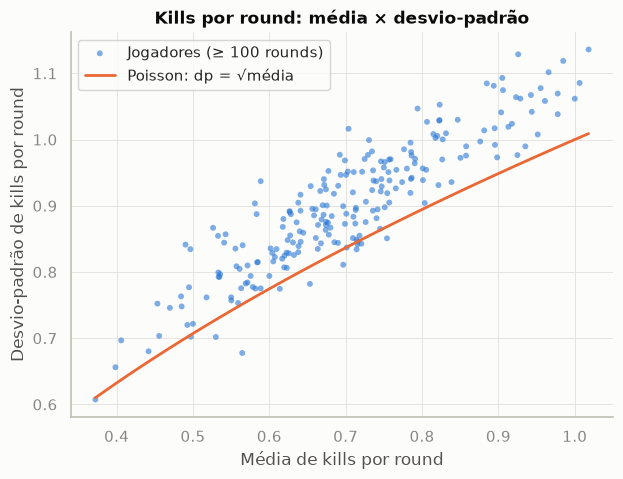

Jogadores analisados: 222
Índice de dispersão (variância/média) — mediana: 1.16


In [33]:
# 1. Kills por round: comparação com a distribuição de Poisson.

# A tabela economia tem uma linha por jogador por round (inclui rounds com 0 kills).
mapa_nick = data.drop_duplicates("puuid").set_index("puuid")["jogador"]
jr = economia[["match_id", "round", "puuid"]].copy()
jr["jogador"] = jr["puuid"].map(mapa_nick)
kills_round = abates.groupby(["match_id", "round", "jogador_killer"]).size().rename("kills")
jr = jr.join(kills_round, on=["match_id", "round", "jogador"]).fillna({"kills": 0})

por_jogador = jr.groupby("puuid")["kills"].agg(["mean", "std", "var", "size"]).query("size >= 100")
medias, desvios = por_jogador["mean"], por_jogador["std"]

grade = np.linspace(medias.min(), medias.max(), 50)
plt.figure(figsize=(7, 5))
plt.scatter(medias, desvios, s=18, alpha=0.6, color=CORES[0], edgecolor="none", label="Jogadores (≥ 100 rounds)")
plt.plot(grade, np.sqrt(grade), color=CORES[1], label="Poisson: dp = √média")
plt.xlabel("Média de kills por round")
plt.ylabel("Desvio-padrão de kills por round")
plt.title("Kills por round: média × desvio-padrão")
plt.legend()
plt.show()

indice_dispersao = (por_jogador["var"] / por_jogador["mean"])
print(f"Jogadores analisados: {len(por_jogador)}")
print(f"Índice de dispersão (variância/média) — mediana: {indice_dispersao.median():.2f}")

O desvio-padrão cresce com a média, como numa Poisson, mas a maioria dos pontos fica **acima** da curva $\sqrt{\lambda}$: a variância é maior que a média (sobredispersão, índice de dispersão mediano ≈ 1,16). Uma Poisson supõe uma taxa constante de abates; no jogo, a taxa muda de round para round (pistol × full buy, ataque × defesa, vantagem numérica) e os abates vêm em rajadas — rounds de 0 kills alternados com multi-kills. Uma mistura de Poissons com taxas diferentes é sobredispersa, e a distribuição binomial negativa costuma descrever melhor esse tipo de contagem.

In [34]:
# 2. Média, variância, desvio-padrão e IQR de cada métrica.

tabela = pd.DataFrame({
    "media": data[metricas].mean(),
    "variancia": data[metricas].var(ddof=1),
    "desvio_padrao": data[metricas].std(ddof=1),
    "iqr": data[metricas].apply(iqr),
})
tabela["coef_variacao"] = tabela["desvio_padrao"] / tabela["media"]
tabela.round(3)

,media,variancia,desvio_padrao,iqr,coef_variacao
acs,202.731,4861.502,69.724,89.977,0.344
adr,134.362,1961.104,44.284,57.622,0.330
kd,1.157,0.794,0.891,0.718,0.770
kast_pct,70.966,212.047,14.562,19.345,0.205
hs_pct,26.626,108.758,10.429,14.192,0.392
fk_round,0.100,0.008,0.089,0.107,0.893
fd_round,0.100,0.007,0.081,0.105,0.816
apr,0.269,0.028,0.166,0.199,0.617
casts_round,2.542,0.534,0.731,0.958,0.288


O **coeficiente de variação** (dp/média) permite comparar a dispersão de métricas com escalas diferentes: first kills/deaths por round são as mais variáveis entre partidas; o KAST é a mais estável.

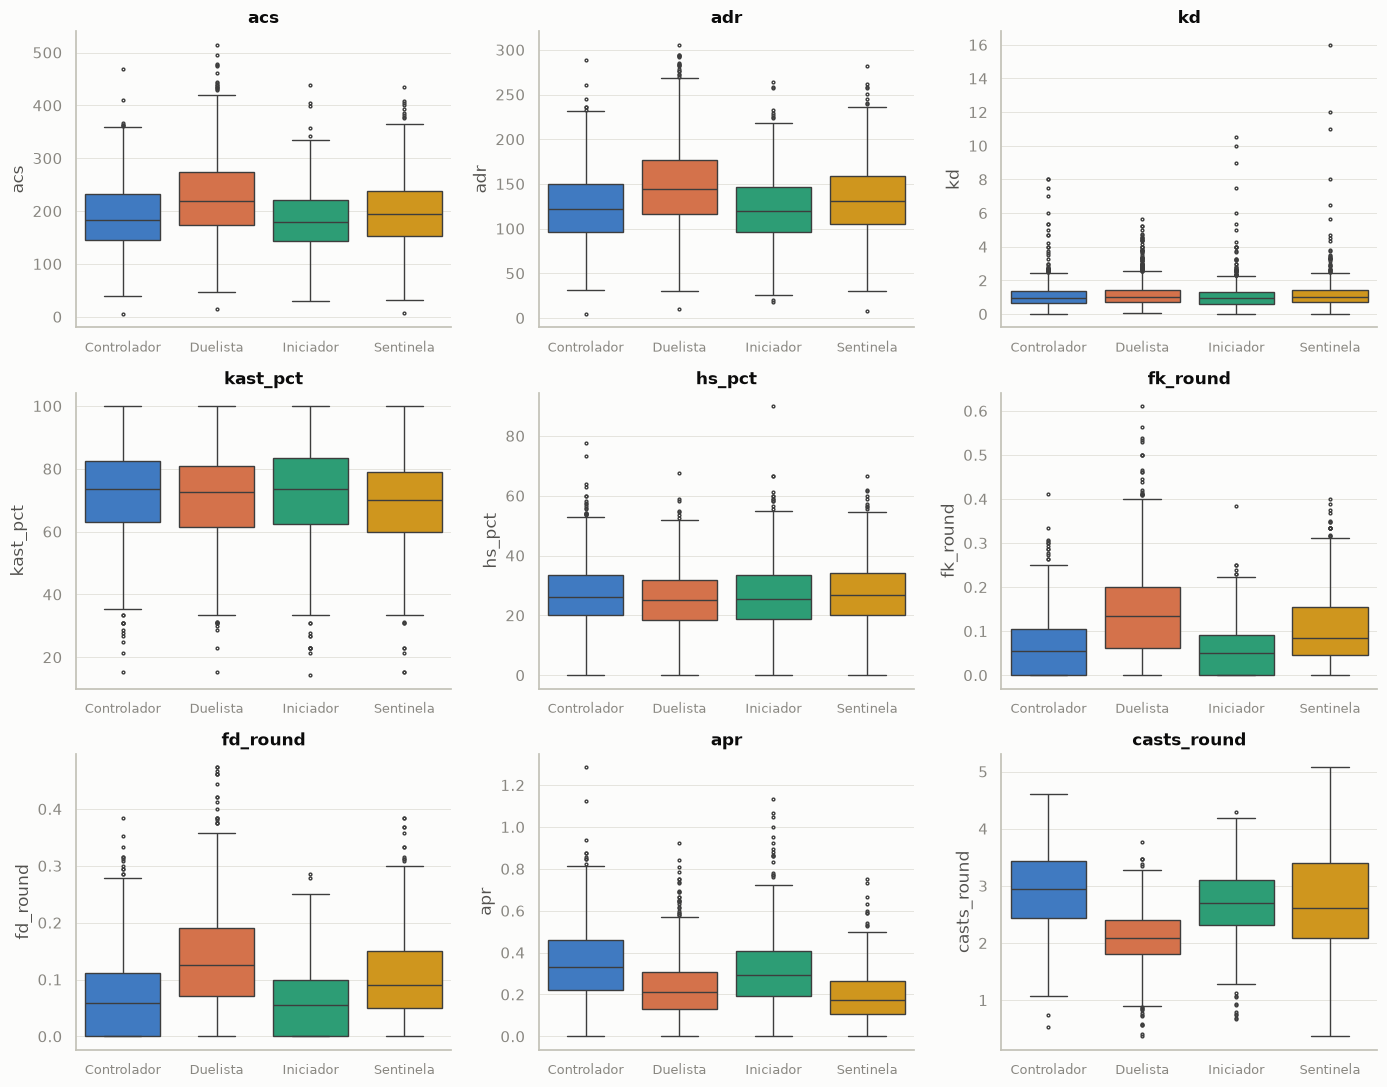

In [35]:
# 3. Boxplot de todas as métricas, separando por função.

fig, axs = plt.subplots(3, 3, figsize=(14, 11))
for ax, coluna in zip(axs.flat, metricas):
    sns.boxplot(data=data, x="funcao", y=coluna, hue="funcao", order=ORDEM_FUNCAO, palette=CORES_FUNCAO,
                legend=False, ax=ax, linewidth=1, fliersize=2)
    ax.set_title(coluna)
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelsize=9)
plt.tight_layout()
plt.show()

In [36]:
# 4. Matriz de Pearson: pares com maior correlação positiva.

corr = data[metricas].corr(method="pearson")
pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna().sort_values(ascending=False)
print("Pares com maior correlação positiva:")
print(pares.head(6).round(3))
print("\nPares com maior correlação negativa:")
print(pares.tail(3).round(3))

Pares com maior correlação positiva:
acs  adr         0.973
     kd          0.594
kd   kast_pct    0.582
acs  fk_round    0.580
adr  kd          0.575
acs  kast_pct    0.547
dtype: float64

Pares com maior correlação negativa:
kd        fd_round      -0.256
fd_round  casts_round   -0.343
kast_pct  fd_round      -0.369
dtype: float64


## 10. Análise do contexto: o que decide rounds e partidas?

Usamos agora as ferramentas da aula para entender o cenário competitivo destes campeonatos universitários.

### 10.1 O que diferencia vencedores e perdedores?

Correlação (ponto-bisserial, equivalente a Pearson com uma variável 0/1) entre cada métrica do jogador e a vitória do seu time.

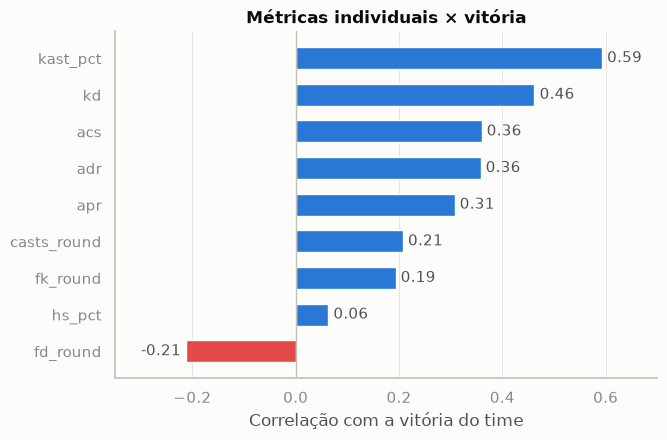

venceu       perdeu  venceu
kast_pct      62.34   79.60
kd             0.75    1.57
acs          177.65  227.81
adr          118.52  150.21
apr            0.22    0.32
casts_round    2.39    2.69
fk_round       0.08    0.12
hs_pct        25.97   27.28
fd_round       0.12    0.08


In [37]:
metricas_vitoria = ["kast_pct", "kd", "acs", "adr", "apr", "casts_round", "fk_round", "hs_pct", "fd_round"]
corr_vitoria = data[metricas_vitoria].apply(lambda s: pearsonr(s, data["venceu"].astype(int))[0]).sort_values()

plt.figure(figsize=(7, 4.5))
plt.barh(corr_vitoria.index, corr_vitoria.values,
         color=[CORES[0] if v > 0 else CORES[7] for v in corr_vitoria.values], height=0.6)
for i, v in enumerate(corr_vitoria.values):
    plt.text(v + (0.01 if v > 0 else -0.01), i, f"{v:.2f}", va="center", ha="left" if v > 0 else "right", color="#52514e")
plt.axvline(0, color="#c3c2b7", linewidth=1)
plt.xlim(-0.35, 0.7)
plt.xlabel("Correlação com a vitória do time")
plt.title("Métricas individuais × vitória")
plt.grid(axis="y", visible=False)
plt.show()

print(data.groupby("venceu")[metricas_vitoria].mean().round(2).T.rename(columns={False: "perdeu", True: "venceu"}))

O **KAST** é a métrica individual mais associada à vitória — mais que KD, ACS ou ADR. Ele mede consistência e jogo coletivo (contribuir em quase todo round, ser trocado quando morre), e não apenas abates. O HS% praticamente não diferencia vencedores e perdedores, e morrer primeiro (`fd_round`) é negativo.

> Cuidado com a causalidade: parte dessa associação é reversa. O time que está vencendo sobrevive mais rounds (aumentando KAST e KD) e acumula equipamento.

### 10.2 Ataque ou defesa: qual lado é favorecido em cada mapa?

          rounds  vitoria_atk  partidas   ic95
mapa                                          
Pearl         60        0.350         3  0.121
Ascent      1672        0.473        86  0.024
Summit       225        0.498        10  0.065
Sunset       478        0.519        24  0.045
Haven       1430        0.530        75  0.026
Lotus       1653        0.532        82  0.024
Split        703        0.538        36  0.037
Fracture      40        0.550         2  0.154
Breeze        92        0.609         5  0.100
Abyss        265        0.611        13  0.059


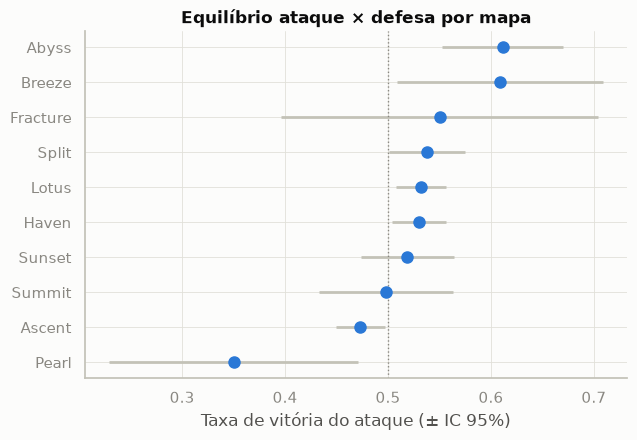

In [38]:
por_mapa = rounds.groupby("mapa").agg(rounds=("atacante_venceu", "size"), vitoria_atk=("atacante_venceu", "mean"))
por_mapa["partidas"] = rounds.groupby("mapa")["match_id"].nunique()
por_mapa = por_mapa.sort_values("vitoria_atk")
# Intervalo de confiança aproximado de 95% para uma proporção.
por_mapa["ic95"] = 1.96 * np.sqrt(por_mapa["vitoria_atk"] * (1 - por_mapa["vitoria_atk"]) / por_mapa["rounds"])
print(por_mapa.round(3))

plt.figure(figsize=(7, 4.5))
plt.errorbar(por_mapa["vitoria_atk"], por_mapa.index, xerr=por_mapa["ic95"], fmt="o", markersize=8,
             color=CORES[0], ecolor="#c3c2b7", elinewidth=2, capsize=0)
plt.axvline(0.5, color="#898781", linestyle=":", linewidth=1)
plt.xlabel("Taxa de vitória do ataque (± IC 95%)")
plt.title("Equilíbrio ataque × defesa por mapa")
plt.show()

No geral o ataque vence 51,8% dos rounds — um equilíbrio quase perfeito. Ascent é o único mapa com amostra grande que pende para a defesa; Haven, Lotus e Split pendem levemente para o ataque. Os extremos (Pearl, Abyss, Breeze) têm poucos rounds e intervalos de confiança largos: **não dá para tirar conclusões com 2 a 5 partidas**.

### 10.3 Momentos decisivos do round

Ataque vence (geral)                         51.8%
Ataque vence após fazer o first kill         75.4%
Ataque vence após sofrer o first kill        32.1%
Ataque vence quando planta a spike           70.8%
Ataque vence sem plantar                      6.7%
Vencedor do pistol vence o round seguinte    86.5%
dtype: str


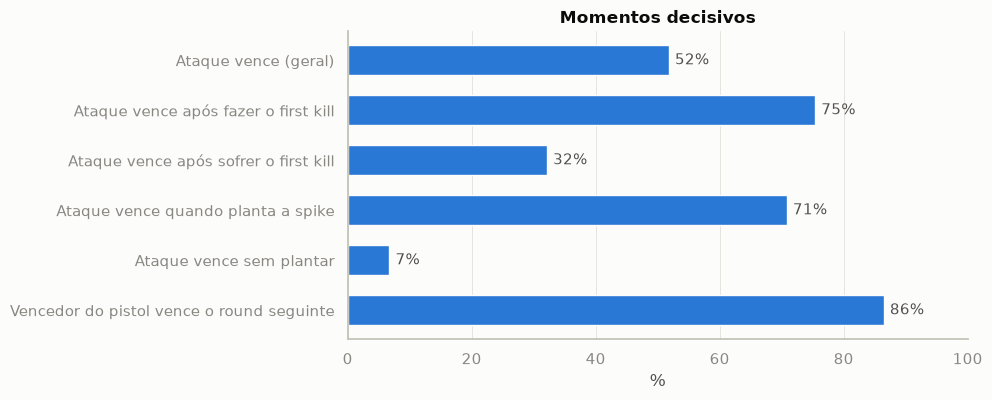

In [39]:
rounds = rounds.sort_values(["match_id", "round"])

# Pistol: o vencedor do pistol vence também o round seguinte?
pistol = rounds[rounds["pistol"]][["match_id", "round", "vencedor"]]
seguinte = rounds[["match_id", "round", "vencedor"]].assign(round=lambda d: d["round"] - 1)
conv = pistol.merge(seguinte, on=["match_id", "round"], suffixes=("", "_seguinte"))

momentos = pd.Series({
    "Ataque vence (geral)": rounds["atacante_venceu"].mean(),
    "Ataque vence após fazer o first kill": rounds.loc[rounds["first_kill_atacante"], "atacante_venceu"].mean(),
    "Ataque vence após sofrer o first kill": rounds.loc[~rounds["first_kill_atacante"], "atacante_venceu"].mean(),
    "Ataque vence quando planta a spike": rounds.loc[rounds["houve_plant"], "atacante_venceu"].mean(),
    "Ataque vence sem plantar": rounds.loc[~rounds["houve_plant"], "atacante_venceu"].mean(),
    "Vencedor do pistol vence o round seguinte": (conv["vencedor"] == conv["vencedor_seguinte"]).mean(),
})
print((momentos * 100).round(1).astype(str) + "%")

plt.figure(figsize=(8, 4))
plt.barh(momentos.index[::-1], momentos.values[::-1] * 100, color=CORES[0], height=0.6)
for i, v in enumerate(momentos.values[::-1] * 100):
    plt.text(v + 1, i, f"{v:.0f}%", va="center", color="#52514e")
plt.xlim(0, 100)
plt.xlabel("%")
plt.title("Momentos decisivos")
plt.grid(axis="y", visible=False)
plt.show()

- **First kill**: o ataque vence 75% dos rounds em que abre com um abate e só 32% quando sofre o primeiro abate. Abrir o round em 5×4 é decisivo — e explica o valor dos duelistas.
- **Plant**: quase todo round do ataque passa pela spike; sem plantar, o ataque só vence 7% dos rounds.
- **Pistol**: o vencedor do pistol ganha 86% dos rounds seguintes, porque o perdedor fica sem dinheiro para comprar.

### 10.4 Economia

Primeiro, a taxa de vitória do ataque em função da vantagem de equipamento (loadout do ataque − loadout da defesa), excluindo os pistol rounds.

                   vantagem  vitoria_atk  rounds
faixa                                           
(-40000, -15000] -16473.043        0.161     230
(-15000, -10000] -12620.932        0.186     590
(-10000, -5000]   -7129.278        0.361     485
(-5000, -2000]    -3284.046        0.463     818
(-2000, 2000]        41.838        0.495    1556
(2000, 5000]       3294.092        0.549     694
(5000, 10000]      7151.263        0.682     475
(10000, 15000]    13009.209        0.812     695
(15000, 40000]    16509.181        0.856     403


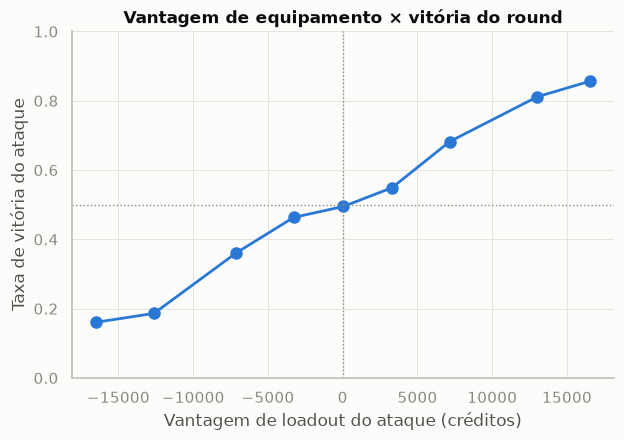

In [40]:
nao_pistol = rounds[~rounds["pistol"]].copy()
nao_pistol["vantagem"] = nao_pistol["loadout_atk"] - nao_pistol["loadout_def"]
faixas = [-40000, -15000, -10000, -5000, -2000, 2000, 5000, 10000, 15000, 40000]
nao_pistol["faixa"] = pd.cut(nao_pistol["vantagem"], bins=faixas)
curva = nao_pistol.groupby("faixa", observed=True).agg(
    vantagem=("vantagem", "mean"), vitoria_atk=("atacante_venceu", "mean"), rounds=("atacante_venceu", "size"))
print(curva.round(3))

plt.figure(figsize=(7, 4.5))
plt.plot(curva["vantagem"], curva["vitoria_atk"], marker="o", markersize=8, color=CORES[0])
plt.axhline(0.5, color="#898781", linewidth=1, linestyle=":")
plt.axvline(0, color="#898781", linewidth=1, linestyle=":")
plt.ylim(0, 1)
plt.xlabel("Vantagem de loadout do ataque (créditos)")
plt.ylabel("Taxa de vitória do ataque")
plt.title("Vantagem de equipamento × vitória do round")
plt.show()

A curva tem formato de "S": com equipamento equivalente (±2 mil créditos) o round é equilibrado (~49%); a partir de ±10 mil créditos de diferença o efeito satura perto de 16–19% (desvantagem) e 81–86% (vantagem). A mesma informação, vista pelo tipo de compra de cada time:

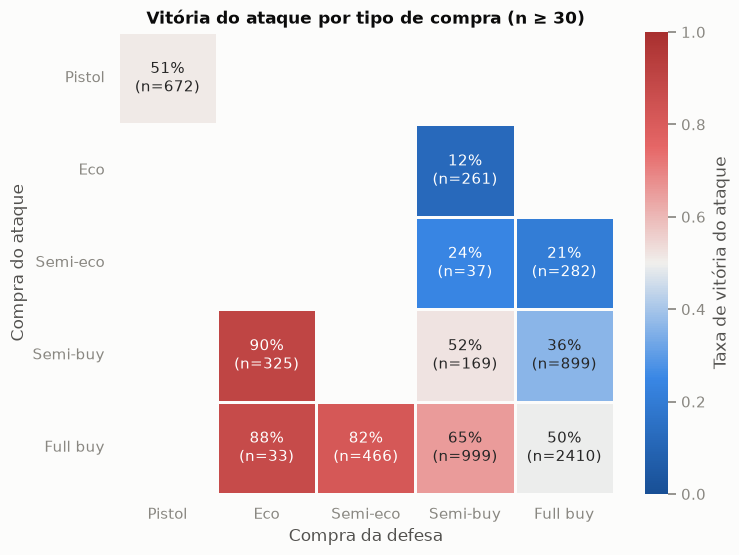

In [41]:
ordem_compra = ["Pistol", "Eco", "Semi-eco", "Semi-buy", "Full buy"]
taxa = pd.crosstab(rounds["compra_atk"], rounds["compra_def"], values=rounds["atacante_venceu"], aggfunc="mean")
contagem = pd.crosstab(rounds["compra_atk"], rounds["compra_def"])
taxa = taxa.reindex(index=ordem_compra, columns=ordem_compra)
contagem = contagem.reindex(index=ordem_compra, columns=ordem_compra).fillna(0).astype(int)

# Mostra apenas combinações com pelo menos 30 rounds.
anot = (taxa * 100).round(0).astype("Int64").astype(str) + "%\n(n=" + contagem.astype(str) + ")"
anot = anot.where(contagem >= 30, "")

plt.figure(figsize=(8, 6))
sns.heatmap(taxa.where(contagem >= 30), annot=anot, fmt="", cmap=CMAP_DIV, vmin=0, vmax=1, center=0.5,
            cbar_kws={"label": "Taxa de vitória do ataque"}, linewidths=1, linecolor="#fcfcfb")
plt.xlabel("Compra da defesa")
plt.ylabel("Compra do ataque")
plt.title("Vitória do ataque por tipo de compra (n ≥ 30)")
plt.yticks(rotation=0)
plt.grid(False)
plt.show()

Com ambos os times em *full buy* o round é um cara ou coroa (≈ 50%). Um time comprado contra um time em *eco* vence ~88–90% das vezes (semi-buy do ataque × eco da defesa: 90%; eco do ataque × semi-buy da defesa: só 12% para o ataque). Curiosamente, *full buy* da defesa contra *semi-buy* do ataque (36% para o ataque) é mais desequilibrado que o inverso (65%): a defesa compensa parte da desvantagem de equipamento com a posição. A classificação de compra segue os limites usados pelo vlr.gg (valor total do time: eco < 5 mil, semi-eco < 10 mil, semi-buy < 20 mil, full buy ≥ 20 mil).

### 10.5 Meta: armas e agentes

Participação nos abates (%):
meio
Vandal      37.3
Phantom     24.1
Sheriff      6.8
Ghost        5.5
Guardian     3.5
Classic      3.5
Operator     3.4
Ability      2.6
Bulldog      2.4
Bandit       2.0
Spectre      2.0
Outlaw       1.0
Name: proportion, dtype: float64


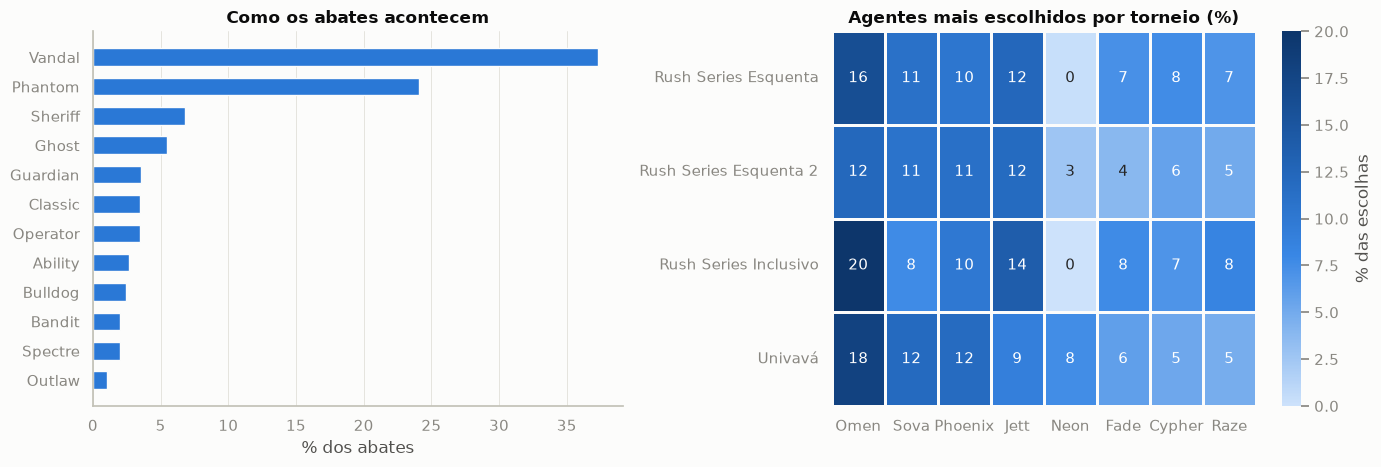

In [42]:
meios = abates["meio"].value_counts(normalize=True).head(12) * 100
print("Participação nos abates (%):")
print(meios.round(1))

fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
axs[0].barh(meios.index[::-1], meios.values[::-1], color=CORES[0], height=0.6)
axs[0].set_xlabel("% dos abates")
axs[0].set_title("Como os abates acontecem")
axs[0].grid(axis="y", visible=False)

top = data["agente"].value_counts().head(8).index
por_torneio = pd.crosstab(data["torneio"], data["agente"], normalize="index")[top] * 100
sns.heatmap(por_torneio, annot=True, fmt=".0f", cmap=CMAP_SEQ, ax=axs[1], vmin=0,
            cbar_kws={"label": "% das escolhas"}, linewidths=1, linecolor="#fcfcfb")
axs[1].set_title("Agentes mais escolhidos por torneio (%)")
axs[1].set_xlabel("")
axs[1].set_ylabel("")
axs[1].grid(False)
plt.tight_layout()
plt.show()

Vandal e Phantom respondem por ~61% dos abates, com clara preferência pela Vandal. Pistolas (Sheriff, Ghost, Classic) somam ~16% — reflexo dos pistol rounds e ecos — e habilidades (`Ability`) menos de 3%. O meta de agentes é estável entre os torneios: o Omen lidera em todos, e Jett, Sova e Phoenix se alternam nas posições seguintes.

### 10.6 Destaques: jogadores e times

In [43]:
jogadores = data.groupby("puuid").agg(
    jogador=("jogador", "first"), time=("time", lambda s: s.mode().iloc[0]), partidas=("match_id", "size"),
    acs=("acs", "mean"), adr=("adr", "mean"), kd=("kd", "median"), kast=("kast_pct", "mean"),
    fk=("fk_round", "mean"), vitorias=("venceu", "mean"),
).query("partidas >= 10").sort_values("acs", ascending=False).set_index("jogador")

print(f"Jogadores com pelo menos 10 partidas: {len(jogadores)}")
print("Correlação entre ACS médio e taxa de vitória dos jogadores:",
      round(pearsonr(jogadores["acs"], jogadores["vitorias"])[0], 2))
jogadores.head(10).round(2)

Jogadores com pelo menos 10 partidas: 127
Correlação entre ACS médio e taxa de vitória dos jogadores: 0.34


,time,partidas,acs,adr,kd,kast,fk,vitorias
jogador,,,,,,,,
lule#dfnt,Macklogic Red,12,293.92,191.27,1.74,81.59,0.24,0.92
bielmonster#prime,Wolf Gaming,16,281.63,182.80,1.19,78.40,0.20,0.69
Kato#lau,Macklogic Red,13,280.44,176.54,1.40,79.58,0.17,0.77
Gutoso#vlr,Ufu Saints,13,277.68,186.03,1.40,74.78,0.21,0.85
AIM Yasuzinn ツ#carol,Green Owls Jacurutu,12,277.48,185.06,1.32,76.94,0.14,0.50
Noya#Lilos,Green Owls Jacurutu,12,275.64,170.59,1.39,79.70,0.11,0.50
CAAP sobrunin#bea,Caap Hellhounds,18,269.41,176.37,1.36,80.16,0.19,0.72
badaBIGBOSS#bagre,Ceub Octopus Vulgaris,16,267.64,177.17,1.85,76.27,0.13,0.50
CAAP SUPERPDR1N#manu,Caap Hellhounds,17,266.39,176.41,1.20,74.39,0.17,0.59


In [44]:
times = data.drop_duplicates(["match_id", "time"]).groupby("time").agg(
    partidas=("match_id", "size"), vitorias=("venceu", "sum"),
    saldo_rounds=("rounds_ganhos_time", "sum"), rounds_contra=("rounds_ganhos_adversario", "sum"))
times["taxa_vitoria"] = times["vitorias"] / times["partidas"]
times["saldo_rounds"] = times["saldo_rounds"] - times["rounds_contra"]
times = times.drop(columns="rounds_contra").query("partidas >= 8").sort_values(["taxa_vitoria", "saldo_rounds"], ascending=False)
times.head(12).round(3)

,partidas,vitorias,saldo_rounds,taxa_vitoria
time,,,,
Ceub Octopus,9,9,76.0,1.000
Macklogic Red,11,10,52.0,0.909
Ufu Saints,18,14,66.0,0.778
Axis Anteaters,13,10,30.0,0.769
Azure Bears Golden,32,24,174.0,0.750
Usp Stars,11,8,25.0,0.727
Caap Hellhounds,18,13,65.0,0.722
Wolf Gaming,16,11,40.0,0.688
Ufmt Turuna,36,23,81.0,0.639


### 10.7 Conclusões e limitações

**Principais achados**

1. **Consistência vence partidas**: o KAST é a métrica individual mais ligada à vitória (r ≈ 0,59), acima de KD e ACS.
2. **Abrir o round é decisivo**: o lado que faz o first kill vence a grande maioria dos rounds; duelistas fazem o dobro de first kills dos demais.
3. **Economia**: o pistol vale, na prática, dois rounds (86% de conversão), e a vantagem de equipamento tem efeito monotônico e não linear (em "S") na vitória do round.
4. **Equilíbrio entre lados**: ataque e defesa estão quase equilibrados (52/48); diferenças por mapa só são confiáveis em Ascent, Lotus, Haven e Split.
5. **Meta estável**: Omen, Sova, Phoenix e Jett lideram em todos os torneios; o agente escolhido depende do mapa.
6. **Métricas redundantes**: ACS ≈ ADR e score ≈ dano ≈ kills; para modelos, usar métricas por round e evitar pares redundantes.

**Limitações**

- Nomes dos times vêm do nome do arquivo; variações como *Inatel*, *Inatel Gray* e *Inatel Legacy* são tratadas como equipes diferentes (o que parece correto, pois chegam a se enfrentar), mas não há como validar com o JSON.
- O KAST usa uma janela de troca de 5 s (convenção da comunidade), e a classificação de compra usa limites fixos.
- Mapas pouco jogados (Fracture, Pearl, Breeze) têm amostra pequena demais para conclusões.
- Associações não implicam causalidade: o loadout e o KAST dos vencedores são, em parte, *consequência* de estarem vencendo.